# **Lab 7(B) - Mathematical and Statistical Filters**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

# OpenCV loads color as BGR, matplotlib expects RGB
def show(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

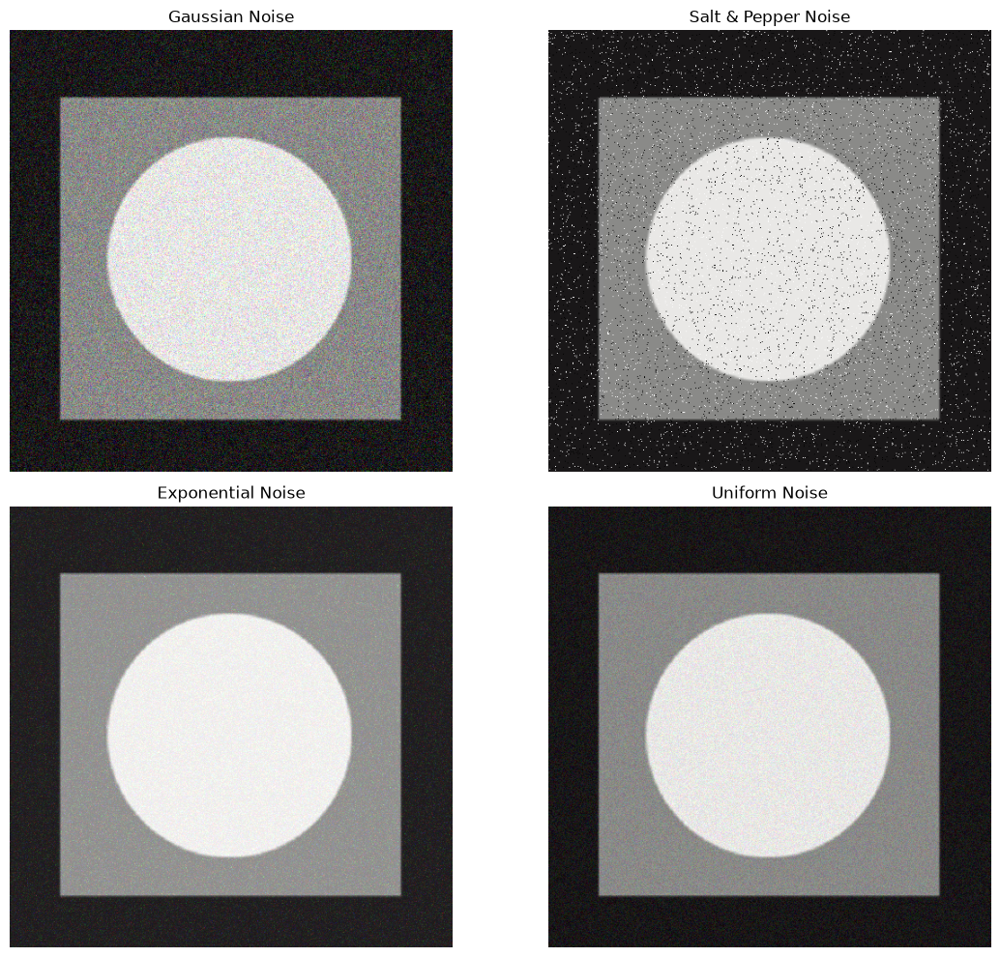

In [2]:
# ========== ( Adding noise to an Image ) =================

# 0. Read the image in COLOR
imgPath = 'noise.jpg'
img = cv2.imread(imgPath)

# 1. Noise function (works for 3-channel images)
def add_noise(image, noise_type):
    row, col, ch = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, image.shape)
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels, all 3 channels)
        num_salt = np.ceil(amount * row * col * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape[:2]]
        noisy[coords[0], coords[1]] = 255
        # Pepper (black pixels, all 3 channels)
        num_pepper = np.ceil(amount * row * col * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape[:2]]
        noisy[coords[0], coords[1]] = 0
        return noisy

    elif noise_type == "exponential":
        expo = np.random.exponential(scale=10.0, size=image.shape)
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, image.shape)
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)


# 2. Generate noisy images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 3. Display in 2x2 grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(show(noise_gauss)), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(show(noise_sp)), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(show(noise_expo)), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(show(noise_uni)), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()

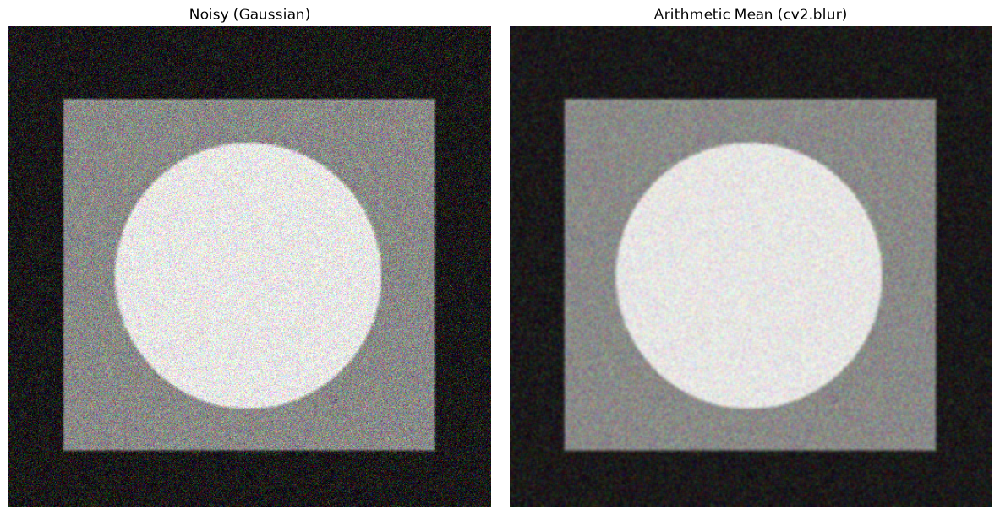

In [3]:
# --- METHOD 1: Using built-in OpenCV function ---
# Change (3, 3) to (5, 5), (7, 7)... for more smoothing
filtered_img = cv2.blur(noise_gauss, (3, 3))

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(show(noise_gauss)), plt.title('Noisy (Gaussian)'), plt.axis('off')
plt.subplot(122), plt.imshow(show(filtered_img)), plt.title('Arithmetic Mean (cv2.blur)'), plt.axis('off')
plt.tight_layout()
plt.show()

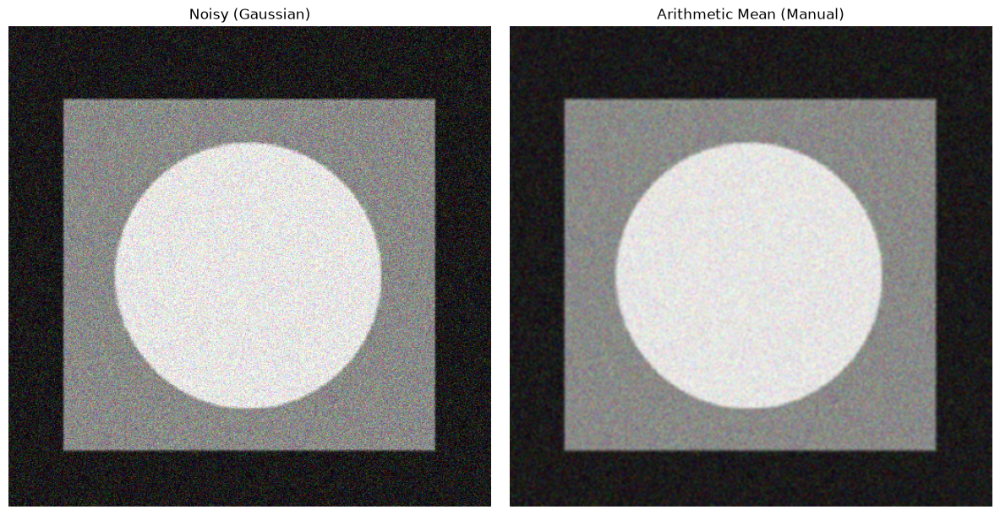

In [4]:
# --- METHOD 2: Manual implementation using a kernel ---
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(show(noise_gauss)), plt.title('Noisy (Gaussian)'), plt.axis('off')
plt.subplot(122), plt.imshow(show(arithmetic_mean_manual)), plt.title('Arithmetic Mean (Manual)'), plt.axis('off')
plt.tight_layout()
plt.show()

## **Geometric Means**

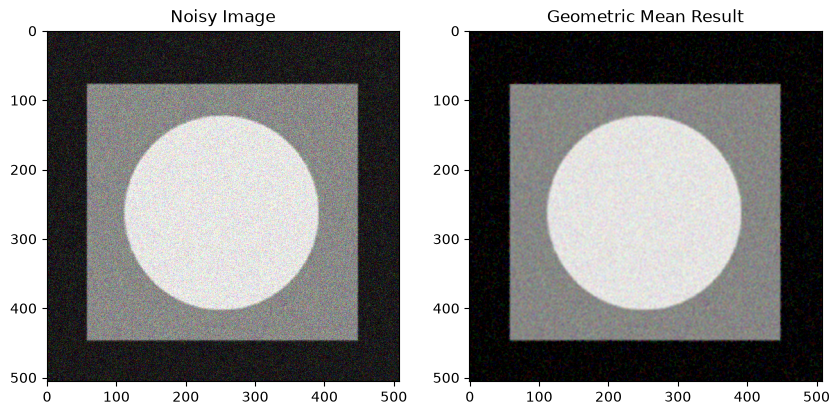

In [5]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Float64 + tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Log transform
    log_img = np.log(img_float)

    # 3. Box filter on the log image (average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Exponent to get the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


noise_img = noise_gauss
result = geometric_mean_filter(noise_img, kernel_size=3)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(show(noise_img)), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(show(result)), plt.title('Geometric Mean Result')
plt.show()


## **Harmonic Means Filter**

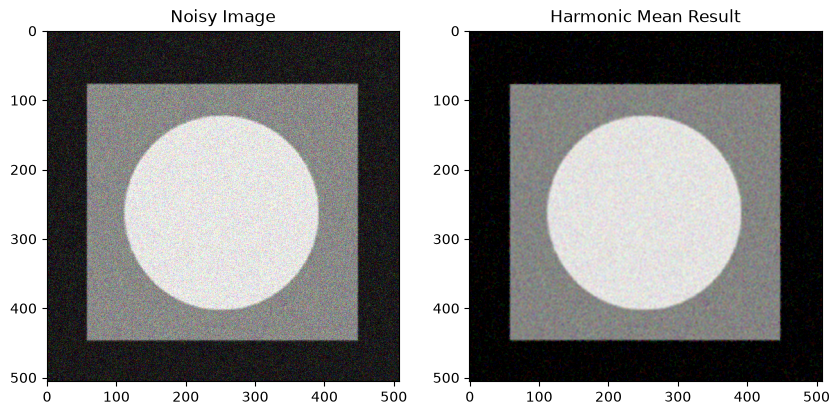

In [6]:
def harmonic_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1e-6

    # Reciprocal of every pixel
    reciprocal_img = 1.0 / img_float

    # Sum of reciprocals in each window
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # (Window size) / (sum of reciprocals)
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


noise_img = noise_gauss
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(show(noise_img)), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(show(cleaned_img)), plt.title('Harmonic Mean Result')
plt.show()

## **Contra - Harmonic Mean Filter**

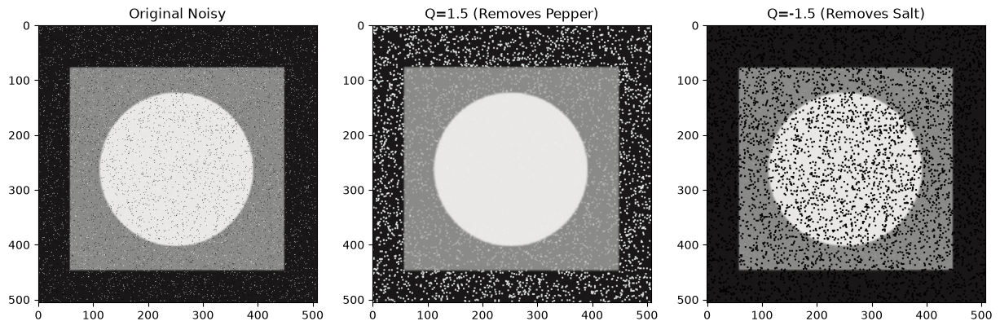

In [7]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    img_float = image.astype(np.float64) + 1e-6

    # Numerator: sum of pixels^(Q+1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # Denominator: sum of pixels^Q
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    result = num_sum / (den_sum + 1e-6)
    return np.clip(result, 0, 255).astype(np.uint8)


# Salt & pepper noise is what this filter is designed for
noise_img = noise_sp

# Q > 0 removes pepper (black spots), Q < 0 removes salt (white spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(show(noise_img)), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(show(pepper_removed)), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(show(salt_removed)), plt.title('Q=-1.5 (Removes Salt)')
plt.show()

## **Median Filter**

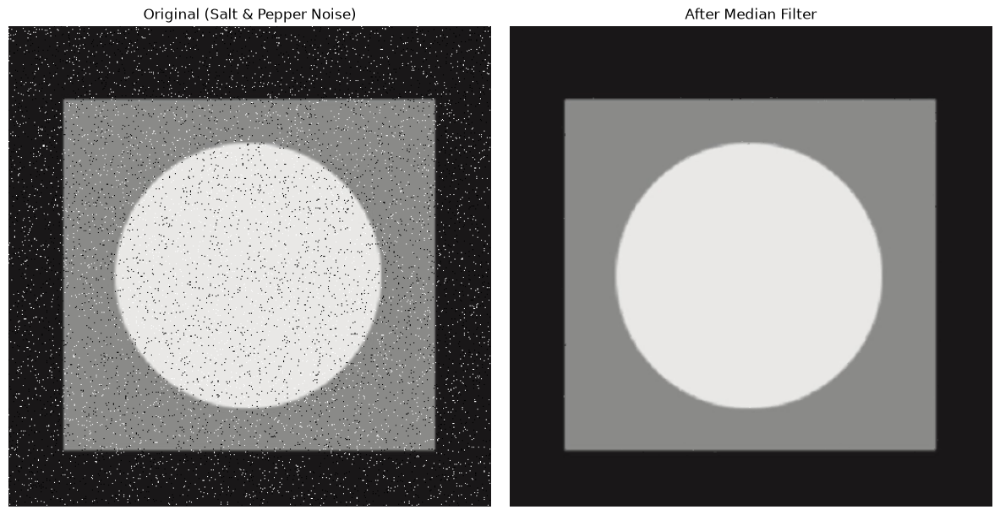

In [8]:
noise_img = noise_sp

# ksize must be an odd integer (3, 5, 7...)
median_result = cv2.medianBlur(noise_img, 3)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(show(noise_img)), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(show(median_result)), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()

## **Max and Min Filter**

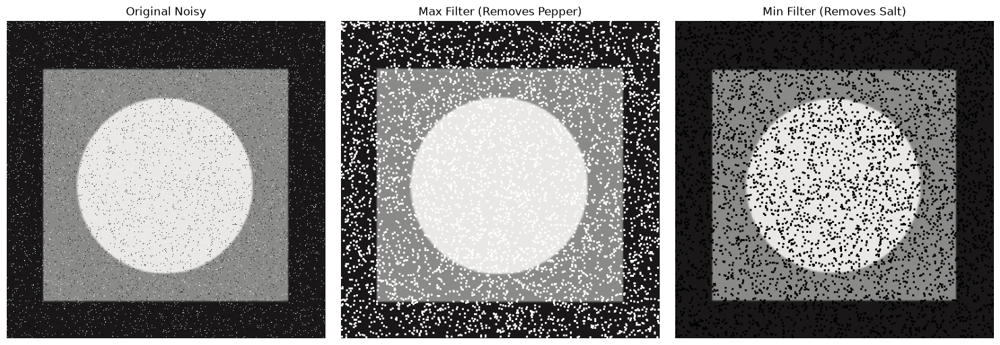

In [9]:
noise_img = noise_sp

kernel = np.ones((3, 3), np.uint8)

# Max filter (dilation): brightest pixel in the neighborhood
max_filter = cv2.dilate(noise_img, kernel)

# Min filter (erosion): darkest pixel in the neighborhood
min_filter = cv2.erode(noise_img, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(show(noise_img)), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(show(max_filter)), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(show(min_filter)), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Mid-Point Filtering**

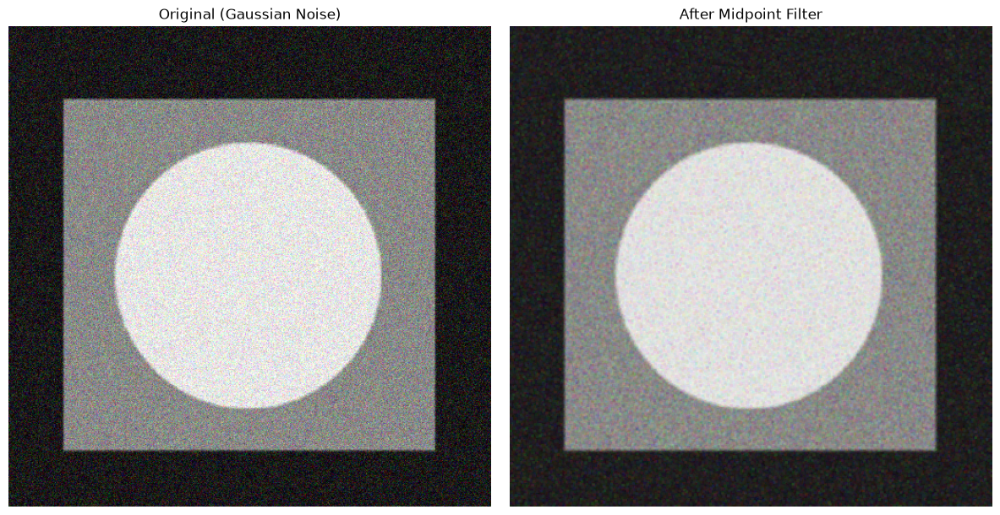

In [10]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    max_img = cv2.dilate(image, kernel).astype(np.float64)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    midpoint = (max_img + min_img) / 2
    return midpoint.astype(np.uint8)


noise_img = noise_gauss
result = midpoint_filter(noise_img, kernel_size=3)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(show(noise_img)), plt.title('Original (Gaussian Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(show(result)), plt.title('After Midpoint Filter'), plt.axis('off')
plt.tight_layout()
plt.show()